# Notebook 63 — 3D representations and geometric intuition

A 2D image normally arrives as a regular array of pixels. A 3D object has no single equivalent representation: it may be stored as points, a mesh, a voxel grid, or a function over continuous space.

This notebook builds intuition for those choices without training a neural network or downloading a dataset. We will represent one synthetic sphere in several ways and examine which questions each representation answers naturally.

Related notes:

- [3D vision and shape representations](../notes/15-3d-vision/3d-vision-and-shape-representations.md)
- [Learning from 3D data](../notes/15-3d-vision/learning-from-3d-data.md)

## Learning goals

- reason about arrays shaped `(number_points, 3)`;
- sample and visualize a point cloud;
- rotate 3D coordinates with a matrix;
- distinguish orthographic and perspective projection;
- convert points into a voxel occupancy grid;
- understand cubic voxel-memory growth;
- query and visualize an implicit occupancy field;
- compare the strengths of explicit and implicit representations.

In [2]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)

## 1. Point clouds are unordered samples

A point cloud containing $P$ points is commonly stored as an array of shape

$$
(P,3).
$$

Each row is one coordinate $(x,y,z)$. The row order has no geometric meaning: permuting the rows must not change the represented set.

To sample a sphere surface uniformly, one convenient method is:

1. draw a 3D vector from an isotropic Gaussian;
2. divide it by its Euclidean norm;
3. multiply by the desired radius.

Normalizing places every vector on the unit sphere. Because the original Gaussian has no preferred direction, the resulting directions are uniformly distributed over the surface.

Background references:

- [Stanford CS229 notes on multivariate Gaussian distributions](https://cs229.stanford.edu/notes_archive/cs229-notes2_old.pdf) — an isotropic Gaussian has equal variance in every direction; the standard case has mean zero and covariance $I$.
- [NumPy documentation for `numpy.linalg.norm`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm) — explains vector norms, `axis`, and why `keepdims=True` preserves a size-one axis for broadcasting.

### Exercise 1 — Sample a sphere point cloud

Complete `sample_sphere_surface`. Generate all random coordinates in one vectorized operation.

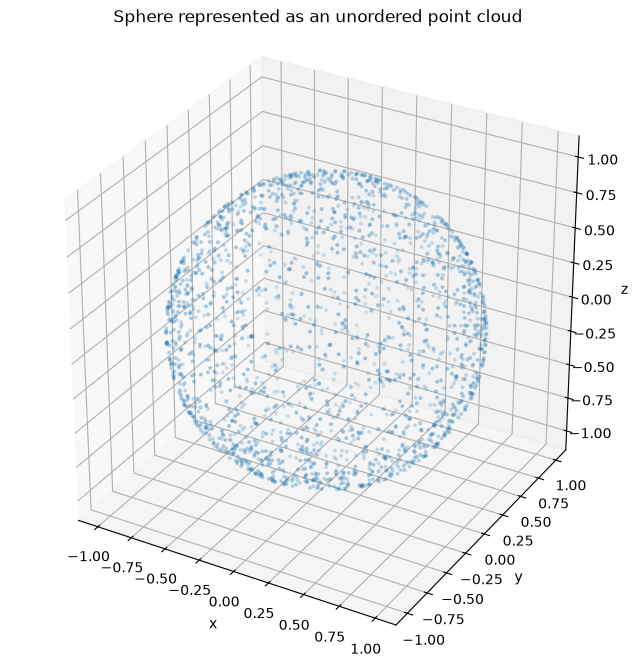

In [3]:
def sample_sphere_surface(number_points, *, radius=1.0, generator=rng):
    """Return uniformly distributed sphere-surface points with shape (P, 3)."""
    # draw Gaussian directions with shape (number_points, 3).
    directions = generator.standard_normal(size=(number_points, 3))
    # calculate one L2 norm per row while preserving the column axis.
    direction_norms = np.linalg.norm(directions, axis=1, keepdims=True)
    # normalize every direction and multiply by radius.
    points = directions / direction_norms * radius
    return points


sphere_points = sample_sphere_surface(2_000, radius=1.0)
assert sphere_points.shape == (2_000, 3)
np.testing.assert_allclose(
    np.linalg.norm(sphere_points, axis=1),
    1.0,
    atol=1e-12,
)

fig = plt.figure(figsize=(8, 8))
axis = fig.add_subplot(projection="3d")
axis.scatter(
    sphere_points[:, 0],
    sphere_points[:, 1],
    sphere_points[:, 2],
    s=4,
    alpha=0.55,
)
axis.set(
    xlabel="x",
    ylabel="y",
    zlabel="z",
    title="Sphere represented as an unordered point cloud",
)
axis.set_box_aspect((1, 1, 1))
plt.show()

### How the calculation works step by step

The array `directions` has shape `(P, 3)`. Each row is one temporary vector:

```text
directions = [[x₁, y₁, z₁],
              [x₂, y₂, z₂],
              ...]
```

The call

```python
direction_norms = np.linalg.norm(directions, axis=1, keepdims=True)
```

calculates the Euclidean length of every row:

$$
\lVert d_i\rVert_2=\sqrt{x_i^2+y_i^2+z_i^2}.
$$

Here `axis=1` means combine the three values across each row. `keepdims=True` preserves the reduced axis, giving shape `(P, 1)` instead of `(P,)`:

| Array | Shape | Meaning |
| --- | --- | --- |
| `directions` | `(P, 3)` | $P$ vectors with $(x,y,z)$ coordinates |
| `direction_norms` | `(P, 1)` | one length for each vector |
| `directions / direction_norms` | `(P, 3)` | the same directions, each rescaled to length one |

NumPy broadcasts each `(P, 1)` length across the corresponding three coordinates. For one concrete vector,

$$
d=(3,4,0),\qquad \lVert d\rVert_2=\sqrt{3^2+4^2+0^2}=5,
$$

so normalization gives

$$
\frac{d}{\lVert d\rVert_2}=\left(\frac35,\frac45,0\right)=(0.6,0.8,0).
$$

Its length is now one. Multiplying by `radius` changes only its length: for radius two, the final point is $(1.2,1.6,0)$ and has length two. The original random magnitude is discarded; only the randomly sampled direction remains.

### Exercise 2 — Verify permutation invariance of the representation

Shuffle the rows of the point cloud. A row-wise comparison should change, but a geometric statistic that ignores order should remain equal.

Here we compare the coordinate-wise minimum, maximum, and mean. These summaries do not prove that two point sets are identical, but they illustrate why point order itself is irrelevant.

In [5]:
# create a random permutation containing every point index once.
permutation = rng.permutation(sphere_points.shape[0])
shuffled_points = sphere_points[permutation]

assert shuffled_points.shape == sphere_points.shape
assert not np.array_equal(shuffled_points, sphere_points)
np.testing.assert_allclose(
    shuffled_points.min(axis=0),
    sphere_points.min(axis=0),
)
np.testing.assert_allclose(
    shuffled_points.max(axis=0),
    sphere_points.max(axis=0),
)
np.testing.assert_allclose(
    shuffled_points.mean(axis=0),
    sphere_points.mean(axis=0),
)

print("original first point:", sphere_points[0])
print("shuffled first point:", shuffled_points[0])

original first point: [ 0.231 -0.789  0.569]
shuffled first point: [ 0.371  0.922 -0.107]


## 2. Rotating points with a matrix

For column-vector notation, rotation around the $z$ axis by angle $\theta$ is

$$
R_z(\theta)=
\begin{bmatrix}
\cos\theta & -\sin\theta & 0 \\
\sin\theta & \cos\theta & 0 \\
0 & 0 & 1
\end{bmatrix}.
$$

The form comes from the ordinary 2D rotation

$$
a'=a\cos\theta-b\sin\theta,\qquad b'=a\sin\theta+b\cos\theta.
$$

A 3D rotation leaves its named axis unchanged and applies this 2D rotation in the perpendicular plane:

| Rotation | Fixed coordinate | Rotated plane |
| --- | --- | --- |
| around $x$ | $x$ | $(y,z)$ |
| around $y$ | $y$ | $(x,z)$ |
| around $z$ | $z$ | $(x,y)$ |

The corresponding matrices are

$$
R_x(\theta)=
\begin{bmatrix}
1&0&0 \\
0&\cos\theta&-\sin\theta \\
0&\sin\theta&\cos\theta
\end{bmatrix},\qquad
R_y(\theta)=
\begin{bmatrix}
\cos\theta&0&\sin\theta \\
0&1&0 \\
-\sin\theta&0&\cos\theta
\end{bmatrix}.
$$

The columns of a rotation matrix show where the original $x$, $y$, and $z$ unit axes move. The signs follow the right-hand rule for a positive angle. For example, $R_z(90^\circ)$ maps the $x$-axis vector $(1,0,0)$ to the $y$-axis vector $(0,1,0)$.

Our points are stored as rows, so all points are transformed together as

$$
X_{rotated}=XR_z^T.
$$

A pure rotation changes orientation but preserves distances and lengths.

### Exercise 3 — Construct and apply a rotation

Complete the rotation matrix and apply it to the point cloud. The sphere looks unchanged because it is rotationally symmetric, so one group of points is highlighted to make the movement visible.

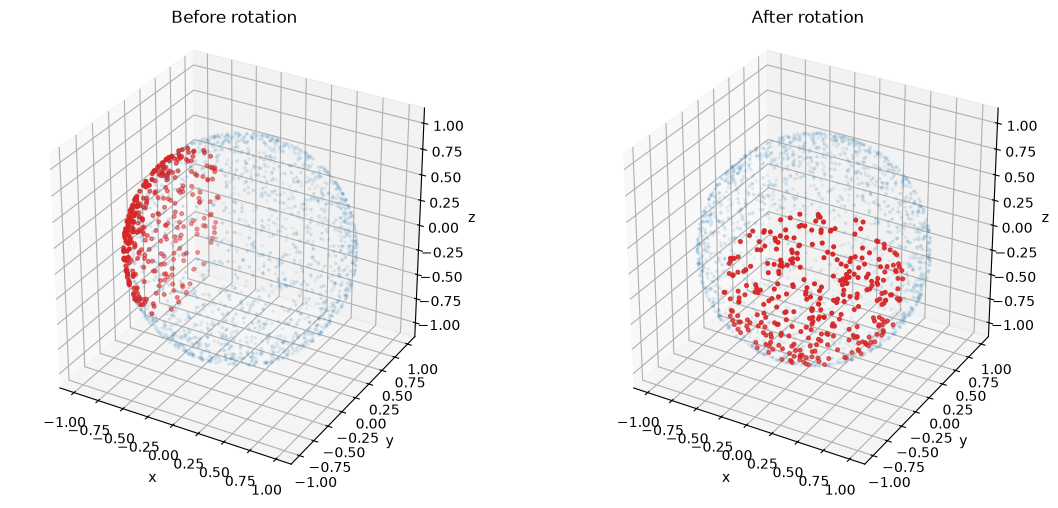

In [17]:
def rotation_z(angle_radians):
    """Return a 3 × 3 matrix for rotation around the z axis."""
    cosine = np.cos(angle_radians)
    sine = np.sin(angle_radians)
    # construct the rotation matrix shown above.
    rotation = np.array(
        [
            [cosine, -sine, 0.0],
            [sine, cosine, 0.0],
            [0.0, 0.0, 1.0],
        ]
    )
    return rotation


angle = np.deg2rad(120.0)
rotation = rotation_z(angle)
rotated_points = sphere_points @ rotation.T

assert rotation.shape == (3, 3)
np.testing.assert_allclose(rotation.T @ rotation, np.eye(3), atol=1e-12)
np.testing.assert_allclose(
    np.linalg.norm(rotated_points, axis=1),
    np.linalg.norm(sphere_points, axis=1),
    atol=1e-12,
)

highlight = sphere_points[:, 0] < -0.65
fig = plt.figure(figsize=(12, 5))
for plot_index, (points, title) in enumerate(
    [(sphere_points, "Before rotation"), (rotated_points, "After rotation")],
    start=1,
):
    axis = fig.add_subplot(1, 2, plot_index, projection="3d")
    axis.scatter(points[~highlight, 0], points[~highlight, 1], points[~highlight, 2], s=3, alpha=0.35)
    axis.scatter(points[highlight, 0], points[highlight, 1], points[highlight, 2], s=7, color="tab:red")
    axis.set(xlabel="x", ylabel="y", zlabel="z", title=title)
    axis.set_box_aspect((1, 1, 1))
plt.tight_layout()
plt.show()

## 3. A 3D object becomes a 2D image through projection

A projection maps camera-space coordinates $(x,y,z)$ to image coordinates.

**Orthographic projection** simply discards depth:

$$
(u,v)=(x,y).
$$

Objects do not become smaller when they move farther away.

A simple **perspective projection** is

$$
(u,v)=\left(f\frac{x}{z},f\frac{y}{z}\right),
$$

where $f$ is focal length and $z>0$ is depth. Dividing by $z$ makes distant objects appear smaller.

This is only a projection exercise: we assume the points are already expressed in camera coordinates and do not model calibration or visibility.

### Exercise 4 — Compare orthographic and perspective projection

Shift the sphere forward so that every point has positive depth, then implement both projections.

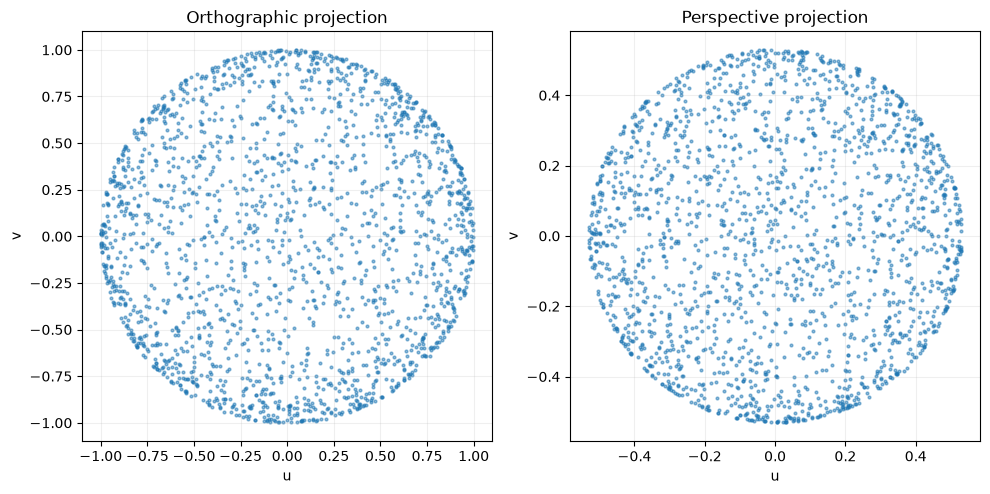

In [19]:
def orthographic_projection(points):
    """Project camera-space points without perspective scaling."""
    # return only the x and y coordinates.
    return np.array(points[:, :2])


def perspective_projection(points, *, focal_length=1.0):
    """Project points using u=f*x/z and v=f*y/z."""
    # verify that all depths are positive.
    if not (points[:, 2:3] > 0).all():
        raise ValueError("All depths must be positive.")
    # divide x and y by depth and multiply by focal length.
    return np.array(points[:, :2] / points[:, 2:3] * focal_length)


camera_points = sphere_points + np.array([0.0, 0.0, 3.0])
orthographic_pixels = orthographic_projection(camera_points)
perspective_pixels = perspective_projection(camera_points, focal_length=1.5)

assert orthographic_pixels.shape == perspective_pixels.shape == (2_000, 2)
np.testing.assert_allclose(orthographic_pixels, camera_points[:, :2])
assert np.isfinite(perspective_pixels).all()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for axis, pixels, title in zip(
    axes,
    (orthographic_pixels, perspective_pixels),
    ("Orthographic projection", "Perspective projection"),
):
    axis.scatter(pixels[:, 0], pixels[:, 1], s=4, alpha=0.5)
    axis.set(title=title, xlabel="u", ylabel="v", aspect="equal")
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Voxelization puts geometry on a regular 3D grid

A voxel grid of resolution $R$ has shape $(R,R,R)$. For points inside the coordinate box $[-1,1]^3$, voxelization consists of:

1. mapping each coordinate from $[-1,1]$ to $[0,R)$;
2. taking the integer cell index;
3. marking that cell as occupied.

Several points may occupy the same voxel. A surface point cloud therefore usually produces a shell of occupied cells rather than a solid object.

### Exercise 5 — Voxelize the sphere surface

Implement `voxelize_points`. Use `np.clip` so a coordinate exactly at the upper bound maps to the final valid index rather than index $R$.

occupied cells: 1,263 / 13,824 (9.1%)


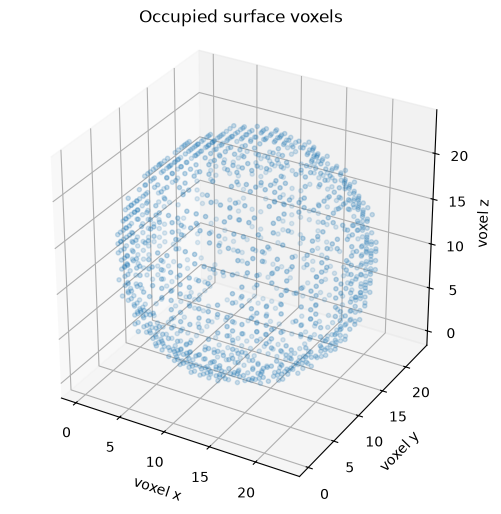

In [41]:
def voxelize_points(points, resolution, *, coordinate_bound=1.0):
    """Return a Boolean occupancy grid for points inside a coordinate cube."""
    if resolution <= 0:
        raise ValueError("resolution must be positive")
    if coordinate_bound <= 0:
        raise ValueError("coordinate_bound must be positive")

    # Shift [-bound, bound] to [0, 2 * bound], divide by the interval
    # width to normalize it to [0, 1], then scale it to [0, resolution].
    # For bound=1 and resolution=4: -1 -> 0, 0 -> 2, and 1 -> 4.
    scaled = (points + coordinate_bound) / (2 * coordinate_bound) * resolution
    # Floor each continuous coordinate to select its containing voxel.
    indices = np.floor(scaled).astype(int)
    # A point exactly at +bound maps to resolution, but the final valid
    # index is resolution - 1, so clip it back into the grid.
    indices = np.clip(indices, 0, resolution - 1)
    # Create the Boolean grid and mark every indexed (x, y, z) cell occupied.
    occupancy = np.zeros((resolution, resolution, resolution), dtype=bool)
    occupancy[indices[:, 0], indices[:, 1], indices[:, 2]] = True
    return occupancy


VOXEL_RESOLUTION = 24
surface_voxels = voxelize_points(
    sphere_points,
    VOXEL_RESOLUTION,
    coordinate_bound=1.0,
)

assert surface_voxels.shape == (24, 24, 24)
assert surface_voxels.dtype == np.bool_
assert 0 < surface_voxels.sum() < surface_voxels.size
print(
    f"occupied cells: {surface_voxels.sum():,} / "
    f"{surface_voxels.size:,} "
    f"({surface_voxels.mean():.1%})"
)

occupied_indices = np.argwhere(surface_voxels)
fig = plt.figure(figsize=(6, 6))
axis = fig.add_subplot(projection="3d")
axis.scatter(
    occupied_indices[:, 0],
    occupied_indices[:, 1],
    occupied_indices[:, 2],
    s=9,
    alpha=0.55,
)
axis.set(
    xlabel="voxel x",
    ylabel="voxel y",
    zlabel="voxel z",
    title="Occupied surface voxels",
)
axis.set_box_aspect((1, 1, 1))
plt.show()

## 5. Dense voxel memory grows cubically

An image with resolution $R\times R$ contains $R^2$ pixels. A dense cubic voxel grid contains $R^3$ cells.

A voxel does **not** inherently require a 32-bit floating-point value. The required type depends on what the grid represents:

| Voxel content | Example storage | Approximate size per value |
| --- | --- | --- |
| Binary empty/occupied flag | Boolean | commonly 1 byte in NumPy |
| Class or material ID | Integer | commonly 1–4 bytes |
| Occupancy probability, signed distance, or density | `float32` | 4 bytes |
| Learned neural feature | several `float32` channels | $4C$ bytes for $C$ channels |

The Boolean grid from Exercise 5 stores only `False` or `True`, so NumPy normally uses approximately one byte per cell. Bit-packed formats can use less. This exercise instead uses one `float32` per voxel because continuous values and floating-point feature grids are common in 3D neural networks.

For one `float32` channel, approximate storage is

$$
R^3\times4\text{ bytes}.
$$

For a neural feature grid with $C$ channels, it becomes

$$
R^3\times C\times4\text{ bytes}.
$$

Doubling $R$ still multiplies the number of cells—and therefore storage at a fixed data type and channel count—by approximately eight. Training uses additional memory for layer activations, gradients, and optimizer state.

### Exercise 6 — Calculate dense-grid memory

Calculate the number of cells and memory for each resolution. Convert bytes to mebibytes using $1024^2$ bytes per MiB.

 16³:       4,096 cells,      0.0 MiB
 32³:      32,768 cells,      0.1 MiB
 64³:     262,144 cells,      1.0 MiB
128³:   2,097,152 cells,      8.0 MiB
256³:  16,777,216 cells,     64.0 MiB
512³: 134,217,728 cells,    512.0 MiB


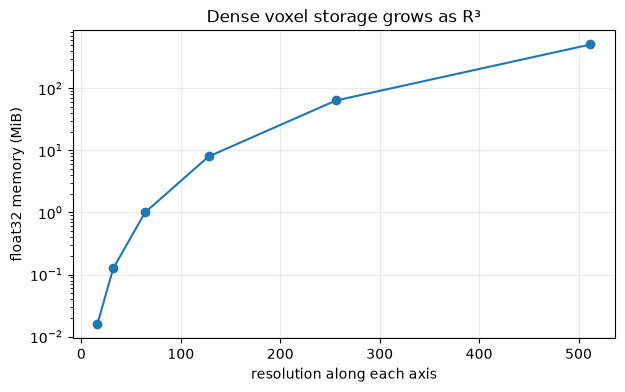

In [43]:
resolutions = np.array([16, 32, 64, 128, 256, 512])

# calculate R^3 cells for each resolution.
number_cells = resolutions ** 3
# calculate memory in MiB for one float32 value per cell.
memory_mib = number_cells * 4 / (1024 ** 2)

np.testing.assert_array_equal(
    number_cells[:3],
    np.array([4_096, 32_768, 262_144]),
)
np.testing.assert_allclose(memory_mib[0], 0.015625)

for resolution, cells, memory in zip(resolutions, number_cells, memory_mib):
    print(f"{resolution:>3}³: {cells:>11,} cells, {memory:>8.1f} MiB")

fig, axis = plt.subplots(figsize=(7, 4))
axis.plot(resolutions, memory_mib, marker="o")
axis.set(
    xlabel="resolution along each axis",
    ylabel="float32 memory (MiB)",
    title="Dense voxel storage grows as R³",
    yscale="log",
)
axis.grid(alpha=0.25)
plt.show()

## 6. An implicit representation answers coordinate queries

The previous exercises stored geometric elements directly: point coordinates, their 2D projections, or occupied voxel cells. In that practical sense, they used **explicit discrete data**. This section instead defines the shape through a function: provide any continuous coordinate and the function reports its relationship to the object.

A voxel grid sits near the boundary between these categories because its interpretation depends on what its stored values mean:

| Voxel-grid use | What is stored | Where is the represented surface? |
| --- | --- | --- |
| Explicit discrete geometry | The cells that belong to the object | The occupied cells themselves form the discrete object |
| Samples of an implicit field | Occupancy probabilities or signed distances | The surface is inferred from a threshold or zero crossing between sampled values |

Exercise 5 uses the first interpretation: a cell touched by a point is marked `True`, and we draw those occupied cells directly. In the second interpretation, the cells are not themselves the surface. For example, neighboring signed-distance values $-0.2$ and $0.1$ indicate that the zero surface passes somewhere between their grid locations. An extraction algorithm can interpolate these values and construct a mesh.

Therefore, the array of field samples is explicitly stored, while the surface described by those values is implicit. In this section we take the idea one step further: instead of storing field samples on a fixed grid, a continuous function evaluates the field at any requested coordinate.

A sphere centered at $c$ with radius $r$ can be defined by the signed function

$$
f(p)=\lVert p-c\rVert_2-r.
$$

Then:

- $f(p)<0$: the point is inside;
- $f(p)=0$: the point is on the surface;
- $f(p)>0$: the point is outside.

This is a signed distance function for a sphere. It represents a continuous object without explicitly listing surface points.

### Exercise 7 — Query an implicit sphere and visualize a slice

Implement the signed distance. Evaluate it on the plane $z=0$ and visualize inside, surface, and outside regions.

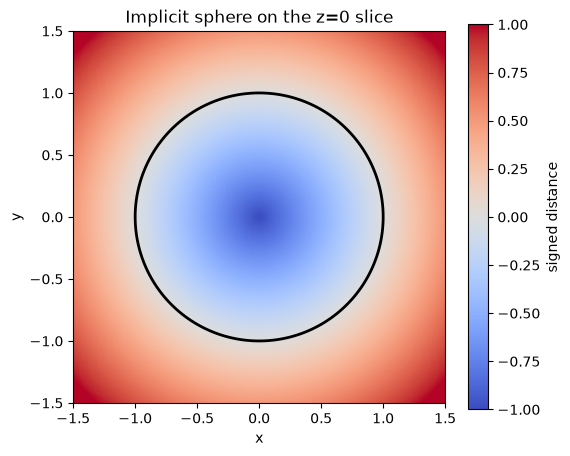

In [46]:
def sphere_signed_distance(points, *, center=None, radius=1.0):
    """Return signed distance from each point to a sphere surface."""
    if center is None:
        center = np.zeros(3)
    center = np.asarray(center)
    # calculate ||point - center||_2 - radius for every row.
    return np.linalg.norm(points - center, axis=1) - radius


query_points = np.array([
    [0.0, 0.0, 0.0],
    [1.0, 0.0, 0.0],
    [1.5, 0.0, 0.0],
])
query_distances = sphere_signed_distance(query_points, radius=1.0)
np.testing.assert_allclose(query_distances, [-1.0, 0.0, 0.5])

coordinates = np.linspace(-1.5, 1.5, 250)
grid_x, grid_y = np.meshgrid(coordinates, coordinates)
slice_points = np.column_stack(
    (grid_x.ravel(), grid_y.ravel(), np.zeros(grid_x.size))
)
signed_distances = sphere_signed_distance(slice_points).reshape(grid_x.shape)

fig, axis = plt.subplots(figsize=(6, 5))
image = axis.imshow(
    signed_distances,
    extent=[coordinates.min(), coordinates.max(), coordinates.min(), coordinates.max()],
    origin="lower",
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
)
axis.contour(grid_x, grid_y, signed_distances, levels=[0.0], colors="black", linewidths=2)
axis.set(
    xlabel="x",
    ylabel="y",
    title="Implicit sphere on the z=0 slice",
    aspect="equal",
)
plt.colorbar(image, ax=axis, label="signed distance")
plt.show()

## 7. One sphere, three representations

The point cloud explicitly lists sampled surface locations. The voxel grid explicitly stores occupied grid cells. The signed-distance function implicitly answers queries anywhere in continuous space.

The following visualization compares them using the representations constructed above.

### Exercise 8 — Visualize the three representations together

Complete the middle-panel slice by selecting one voxel index along the $z$ axis. Then consider what information is lost or introduced by each conversion.

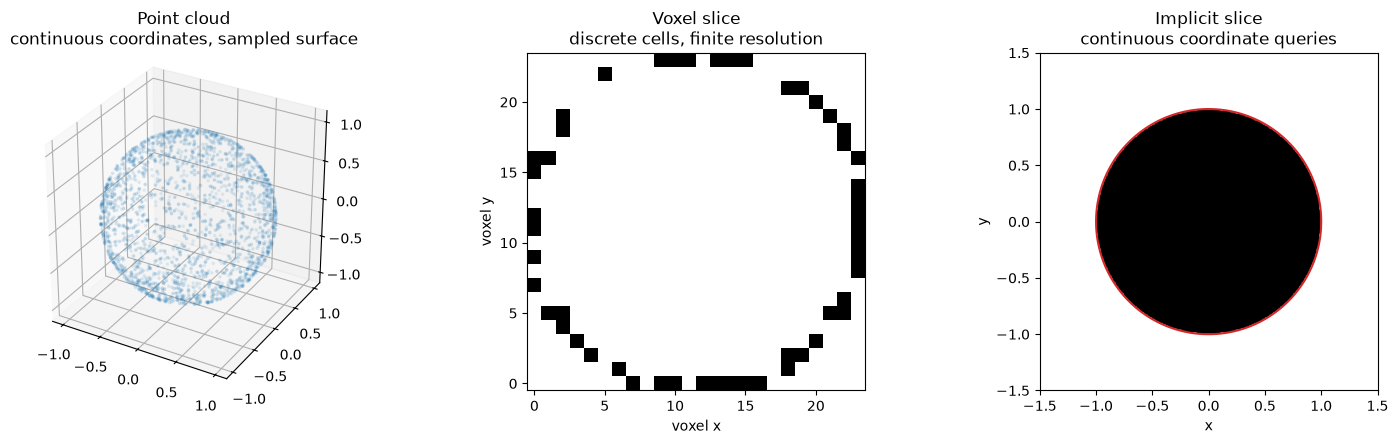

In [47]:
# choose the central z index of the voxel grid.
middle_z = VOXEL_RESOLUTION // 2

fig = plt.figure(figsize=(15, 4.5))

axis_points = fig.add_subplot(1, 3, 1, projection="3d")
axis_points.scatter(
    sphere_points[:, 0],
    sphere_points[:, 1],
    sphere_points[:, 2],
    s=3,
    alpha=0.4,
)
axis_points.set_title("Point cloud\ncontinuous coordinates, sampled surface")
axis_points.set_box_aspect((1, 1, 1))

axis_voxels = fig.add_subplot(1, 3, 2)
axis_voxels.imshow(surface_voxels[:, :, middle_z].T, origin="lower", cmap="gray_r")
axis_voxels.set_title("Voxel slice\ndiscrete cells, finite resolution")
axis_voxels.set(xlabel="voxel x", ylabel="voxel y")

axis_implicit = fig.add_subplot(1, 3, 3)
axis_implicit.imshow(
    signed_distances <= 0,
    extent=[coordinates.min(), coordinates.max(), coordinates.min(), coordinates.max()],
    origin="lower",
    cmap="gray_r",
)
axis_implicit.contour(grid_x, grid_y, signed_distances, levels=[0.0], colors="tab:red")
axis_implicit.set_title("Implicit slice\ncontinuous coordinate queries")
axis_implicit.set(xlabel="x", ylabel="y", aspect="equal")

plt.tight_layout()
plt.show()

## 8. What this notebook leaves out

This notebook intentionally avoids several substantial topics:

- mesh connectivity and mesh-processing algorithms;
- camera calibration and pose estimation;
- occlusion and visibility during projection;
- sparse voxel structures such as octrees;
- learned point-cloud models;
- extracting a mesh from an implicit field;
- neural rendering.

Finalized, validated versions of the geometry helpers are available in [`cs231n_practice/geometry.py`](../cs231n_practice/geometry.py). The notebook retains its local implementations so the calculations remain visible as exercises.

## Reflection

Answer briefly after completing the exercises.

1. Why is a point cloud represented as a set rather than an ordered sequence?

   **Answer:** A point cloud represents an unordered set because changing the row order does not change the geometry. Point-cloud models should therefore be permutation invariant.

2. Why does multiplying row-stored points by $R^T$ apply the column-vector rotation $R$?

   **Answer:** The usual formula assumes a column point, $p'=Rp$. A stored row is $p^T$, and transposing the equation gives $(p')^T=p^TR^T$. Therefore row-stored points multiply by $R^T$.

3. What visual difference did you observe between orthographic and perspective projection?

   **Answer:** Orthographic projection ignores depth, so apparent size stays constant. Perspective projection divides by depth, making farther points appear closer together and smaller.

4. Why does a surface point cloud create a voxel shell rather than a solid sphere?

   **Answer:** We sampled only points on the sphere’s surface. Voxelization marks only cells touched by those points, so the interior remains empty and the result is a shell.

5. Why does doubling voxel resolution require approximately eight times more dense storage?

   **Answer:** Resolution doubles along all three axes, so the number of cells changes by $2\times2\times2=2^3=8$.

6. Which query is easier for the implicit sphere than for the point cloud?

   **Answer:** Testing whether an arbitrary coordinate is inside, on, or outside the sphere is easier with the implicit function.

7. What information does a mesh provide that the point cloud used here does not?

   **Answer:** A mesh provides connectivity: its faces describe which vertices are neighbors and how they form a continuous surface.

8. When might you choose points, voxels, or an implicit field?

   **Answer:** Choose points for sparse sensor samples, voxels for regular grid processing such as 3D convolutions, and an implicit field for continuous coordinate queries and smooth surfaces.